1) **La tarifa en vivo**

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

tarifas = pd.read_csv("https://www.datos.gov.co/resource/c698-wqig.csv?$limit=60000")
tarifas["año"] = tarifas["costounitariotarifa_ano"].astype(str).str.replace(",", "").astype(int)
tarifas["valor"] = pd.to_numeric(tarifas["costounitariotarifa_valor_tarifa"], errors="coerce")
res = tarifas[tarifas["claseservicio_descri"].str.contains("Residencial Estrato", na=False)]

print("Tamaño:", tarifas.shape)
print("a) Mercados:\n", tarifas["mercado_nombre"].value_counts())
print("b) Años:", tarifas["año"].min(), "a", tarifas["año"].max())
print("c) Estratos:", sorted(res["claseservicio_estrato"].unique()),
      "| Rangos de consumo:", sorted(tarifas["costounitariotarifa_rangoconsumo"].unique()))
print("d) NaN:\n", tarifas.isna().sum()[lambda s: s > 0])
print("Dominio de valor:", tarifas["valor"].min(), "a", tarifas["valor"].max(), "$/kWh")

Tamaño: (40609, 26)
a) Mercados:
 mercado_nombre
CHEC       37683
PEREIRA     2926
Name: count, dtype: int64
b) Años: 2008 a 2026
c) Estratos: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0)] | Rangos de consumo: [np.int64(1), np.int64(2)]
d) NaN:
 claseservicio_estrato                   25266
costounitariotarifa_distribucion           11
costounitariotarifa_comercializacion       11
costounitariotarifa_perdidas               11
costounitariotarifa_restricciones          11
costounitariotarifa_subcon                 11
dtype: int64
Dominio de valor: 102.1672 a 1336.8041 $/kWh


2. **La tarifa como función**

In [ ]:
CS = 130  # consumo de subsistencia en Manizales (kWh/mes)

base = tarifas.query('mercado_nombre == "CHEC" and costounitariotarifa_tipomercado == "R" and '
                     'nivel_tension_codigo == 1 and modalidadcobro_propiedad == "0% OR" and '
                     'año == 2026 and costounitariotarifa_mes == 8')
base = base[base["claseservicio_descri"].str.contains("Residencial Estrato", na=False)]

pliego = base.pivot_table(index="claseservicio_estrato", columns="costounitariotarifa_rangoconsumo",
                          values="valor", aggfunc="median")
pliego.columns = ["sub", "plena"]
pliego["plena"] = pliego["plena"].fillna(pliego["sub"])  # estratos 4-6: un solo precio
print(pliego.round(2))

def valor_factura(kwh, estrato):
    sub, plena = pliego.loc[estrato]
    return min(kwh, CS) * sub + max(kwh - CS, 0) * plena

# Prueba contra el recibo: 92 kWh, estrato 4, pagó $82.302 por energía
print(f"Modelo: ${valor_factura(92, 4):,.0f} | Recibo: $82,302")

                           sub    plena
claseservicio_estrato                  
1.0                     422.62   894.58
2.0                     528.28   894.58
3.0                     760.40   894.58
4.0                     894.58   894.58
5.0                    1073.50  1073.50
6.0                    1073.50  1073.50
Modelo: $82,302 | Recibo: $82,302


3. **La desición de modelación**

In [ ]:
# 3) La decisión de modelación: estratos con las proporciones REALES de Manizales (DANE, CNPV 2018)
df = pd.read_csv("https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/londres_mensual.csv")
manizales = pd.Series([15.19, 25.56, 36.60, 11.88, 4.14, 6.63], index=range(1, 7)) / 100

mediana = df.groupby("hogar")["kwh"].median()
estrato = pd.qcut(mediana, [0, *manizales.cumsum()], labels=range(1, 7)).astype(int)
df["estrato"] = df["hogar"].map(estrato)
df["valor"] = [valor_factura(k, e) for k, e in zip(df["kwh"], df["estrato"])]

print(pd.DataFrame({"% Manizales": manizales * 100,
                    "% Londres": estrato.value_counts(normalize=True) * 100,
                    "kWh mediano": mediana.groupby(estrato).median(),
                    "factura mediana $": df.groupby("estrato")["valor"].median()}).round(1))

   % Manizales  % Londres  kWh mediano  factura mediana $
1         15.2       15.2         95.0            39967.6
2         25.6       25.6        170.1           103153.8
3         36.6       36.6        290.0           240697.0
4         11.9       11.9        449.9           402232.2
5          4.1        4.1        570.5           612368.4
6          6.6        6.6        783.3           856107.0


  
  4.**La nube. Parte a**


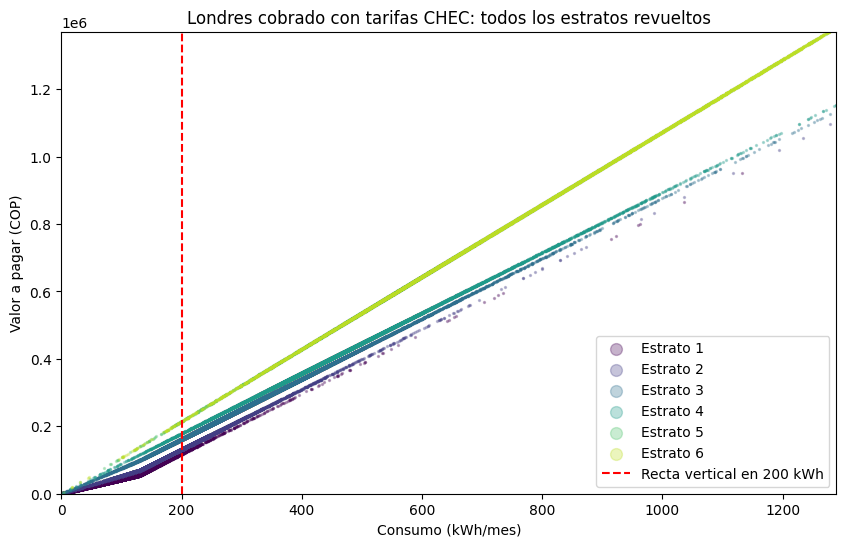

In [ ]:
colores = plt.cm.viridis(np.linspace(0, 0.9, 6))

fig, ax = plt.subplots(figsize=(10, 6))
for e in range(1, 7):
    g = df[df["estrato"] == e]
    ax.scatter(g["kwh"], g["valor"], s=2, alpha=0.3, color=colores[e-1], label=f"Estrato {e}")
ax.axvline(200, color="red", ls="--", lw=1.5, label="Recta vertical en 200 kWh")
ax.set_xlim(0, df["kwh"].quantile(0.99))
ax.set_ylim(0, df["valor"].quantile(0.99))
ax.set_xlabel("Consumo (kWh/mes)"); ax.set_ylabel("Valor a pagar (COP)")
ax.set_title("Londres cobrado con tarifas CHEC: todos los estratos revueltos")
ax.legend(markerscale=6); plt.show()

4.**Parte b**

In [ ]:
import pandas as pd

prueba = pd.DataFrame({"estrato": range(1, 7),
                       "valor con 200 kWh": [valor_factura(200, e) for e in range(1, 7)]})
print(prueba.round(0).to_string(index=False))
print("\nValores distintos para el mismo consumo:", prueba["valor con 200 kWh"].round(2).nunique())

 estrato  valor con 200 kWh
       1           117562.0
       2           131297.0
       3           161473.0
       4           178917.0
       5           214700.0
       6           214700.0

Valores distintos para el mismo consumo: 5


4.**Parte c**

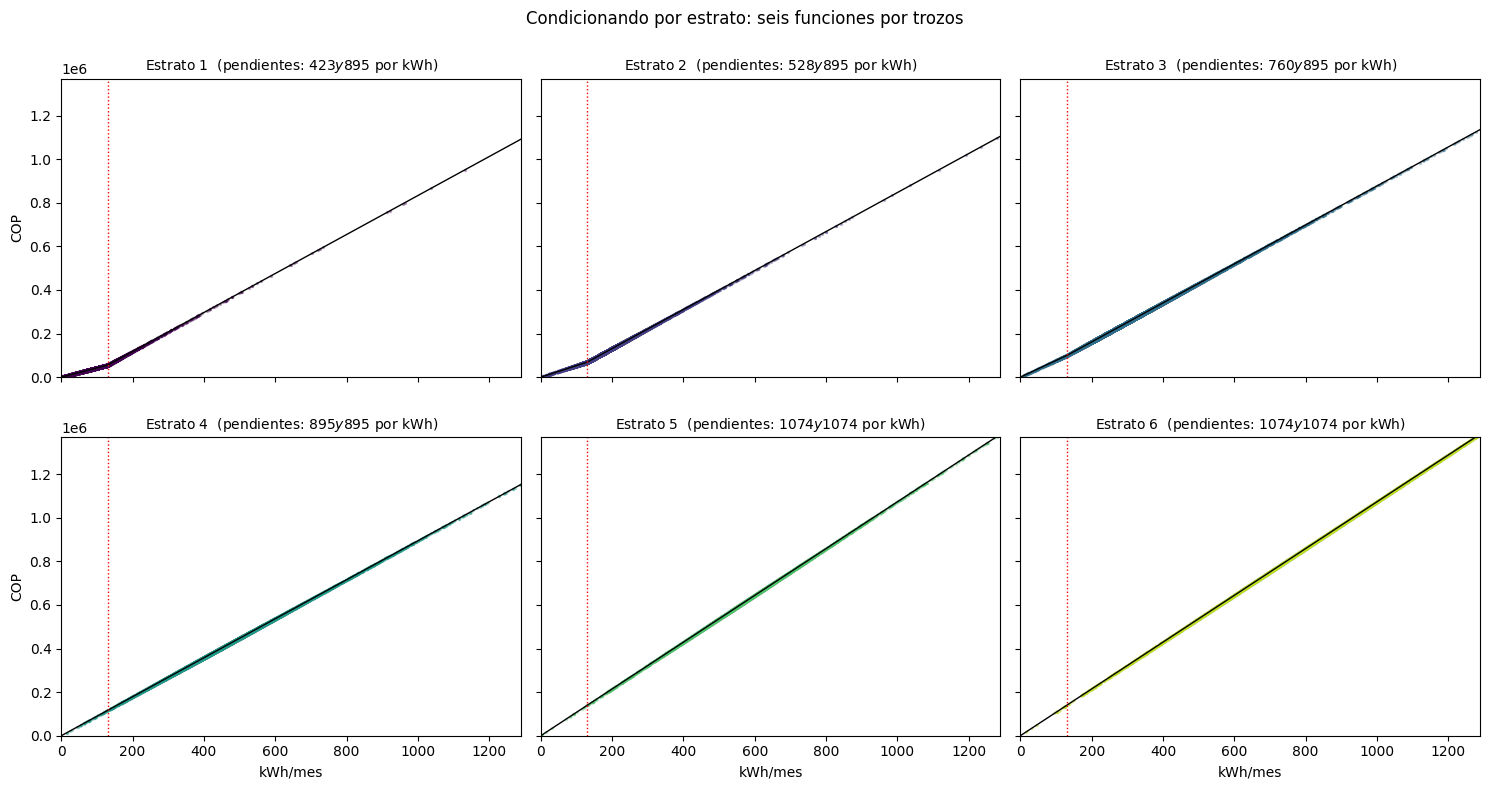

¿Algún consumo con más de un valor dentro del mismo estrato? False


In [ ]:
# Condicionar por estrato: una gráfica por cada estrato
fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
xmax = df["kwh"].quantile(0.99)
for ax, e in zip(axs.flat, range(1, 7)):
    g = df[df["estrato"] == e]
    ax.scatter(g["kwh"], g["valor"], s=2, alpha=0.3, color=colores[e-1])
    k = np.linspace(0, xmax, 300)                                    # la regla f_e
    ax.plot(k, [valor_factura(x, e) for x in k], color="black", lw=1)
    ax.axvline(CS, color="red", ls=":", lw=1)                        # quiebre en 130 kWh
    ax.set_title(f"Estrato {e}  (pendientes: ${pliego.loc[e,'sub']:.0f} y ${pliego.loc[e,'plena']:.0f} por kWh)", fontsize=10)
axs[1, 0].set_xlabel("kWh/mes"); axs[1, 1].set_xlabel("kWh/mes"); axs[1, 2].set_xlabel("kWh/mes")
axs[0, 0].set_ylabel("COP"); axs[1, 0].set_ylabel("COP")
ax.set_xlim(0, xmax); ax.set_ylim(0, df["valor"].quantile(0.99))
fig.suptitle("Condicionando por estrato: seis funciones por trozos"); plt.tight_layout(); plt.show()

# Comprobación: dentro de un estrato, un mismo consumo da un solo valor
rep = df.groupby(["estrato", "kwh"])["valor"].nunique()
print("¿Algún consumo con más de un valor dentro del mismo estrato?", (rep > 1).any())

5.**Cuantificar** Estrato 3: de 110 a 135 kWh vs. de 135 a 160 kWh

In [ ]:
d1 = valor_factura(135, 3) - valor_factura(110, 3)
d2 = valor_factura(160, 3) - valor_factura(135, 3)
print(f"De 110 a 135 kWh (+25 kWh): paga ${d1:,.0f} más")
print(f"De 135 a 160 kWh (+25 kWh): paga ${d2:,.0f} más")
print(f"Diferencia: ${d2 - d1:,.0f}")

# Auditoría: la misma cuenta a mano
T3, P3 = pliego.loc[3, "sub"], pliego.loc[3, "plena"]
print(f"\nT3 (subsidiado) = ${T3:,.2f}/kWh   P3 (pleno) = ${P3:,.2f}/kWh")
print(f"A mano: Δ1 = 20·T3 + 5·P3 = ${20*T3 + 5*P3:,.0f}")
print(f"A mano: Δ2 = 25·P3        = ${25*P3:,.0f}")
print("¿Coincide con la función?", np.isclose(d1, 20*T3 + 5*P3) and np.isclose(d2, 25*P3))

De 110 a 135 kWh (+25 kWh): paga $19,681 más
De 135 a 160 kWh (+25 kWh): paga $22,365 más
Diferencia: $2,684

T3 (subsidiado) = $760.40/kWh   P3 (pleno) = $894.58/kWh
A mano: Δ1 = 20·T3 + 5·P3 = $19,681
A mano: Δ2 = 25·P3        = $22,365
¿Coincide con la función? True


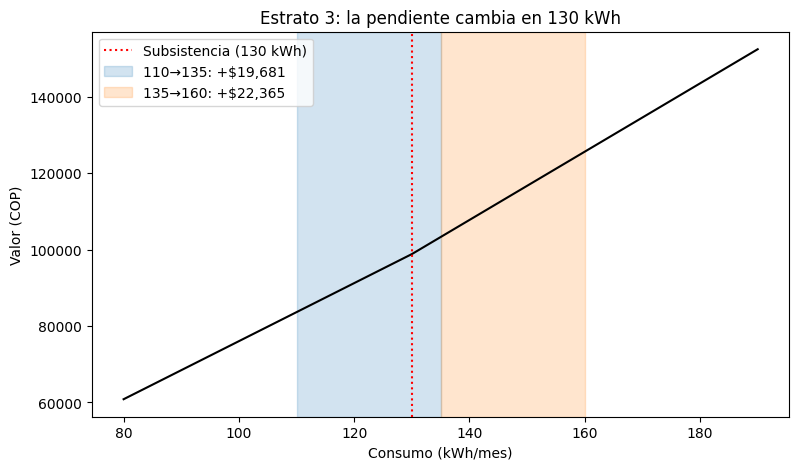

In [ ]:
# Gráfica de los dos saltos sobre la función del estrato 3
k = np.linspace(80, 190, 300)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k, [valor_factura(x, 3) for x in k], color="black")
ax.axvline(CS, color="red", ls=":", label="Subsistencia (130 kWh)")
ax.axvspan(110, 135, alpha=0.2, color="tab:blue",   label=f"110→135: +${d1:,.0f}")
ax.axvspan(135, 160, alpha=0.2, color="tab:orange", label=f"135→160: +${d2:,.0f}")
ax.set_xlabel("Consumo (kWh/mes)"); ax.set_ylabel("Valor (COP)")
ax.set_title("Estrato 3: la pendiente cambia en 130 kWh"); ax.legend(); plt.show()

5.**Parte b** Matriz de correlación de las variables numéricas

           kwh  valor  estrato
kwh      1.000  0.995    0.775
valor    0.995  1.000    0.801
estrato  0.775  0.801    1.000


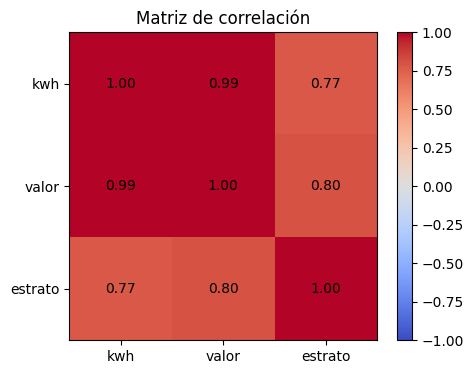

In [ ]:
matriz = df[["kwh", "valor", "estrato"]].corr()
print(matriz.round(3))

plt.figure(figsize=(5, 4))
plt.imshow(matriz, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(3), matriz.columns); plt.yticks(range(3), matriz.columns)
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{matriz.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(); plt.title("Matriz de correlación"); plt.show()

6.**El microdataset del curso.  parte a**

In [ ]:
mi_fila = pd.DataFrame([{
    "codigo_anonimo": "E01",       # un código, NUNCA el nombre
    "mes": "2026-09",              # mes del recibo (AAAA-MM)
    "kwh": 92,                     # consumo del mes
    "valor_pagado": 82302,         # valor de energía del recibo
    "estrato": 4}])
mi_fila["valor_modelo"] = [valor_factura(k, e) for k, e in zip(mi_fila["kwh"], mi_fila["estrato"])]
mi_fila["diferencia"] = mi_fila["valor_pagado"] - mi_fila["valor_modelo"]
mi_fila

,codigo_anonimo,mes,kwh,valor_pagado,estrato,valor_modelo,diferencia
0,E01,2026-09,92,82302,4,82301.8108,0.1892


6.**Parte b** Pintar los puntos del curso sobre la nube de Londres

Puntos del curso: 1


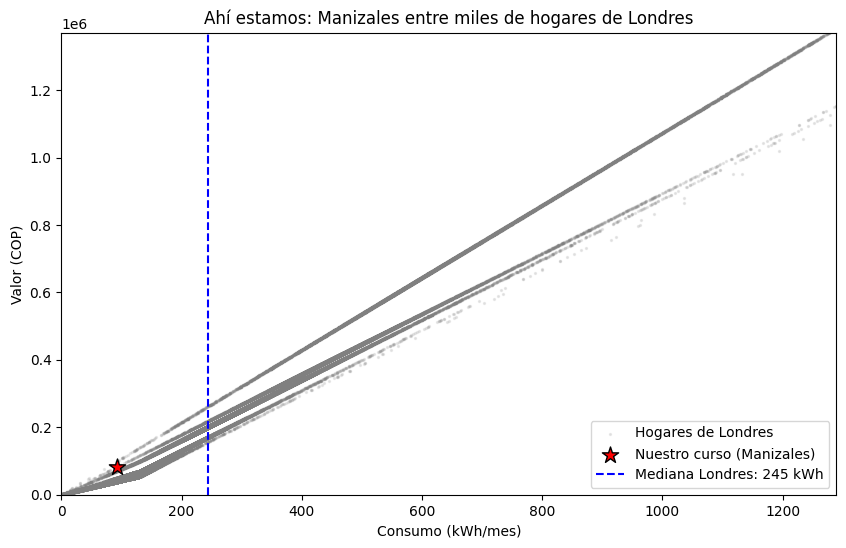

In [ ]:
URL_CURSO = ""   # ej: "https://docs.google.com/spreadsheets/d/.../export?format=csv"

curso = pd.read_csv(URL_CURSO) if URL_CURSO else mi_fila
print("Puntos del curso:", len(curso))

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df["kwh"], df["valor"], s=2, alpha=0.15, color="gray", label="Hogares de Londres")
ax.scatter(curso["kwh"], curso["valor_pagado"], s=150, marker="*", color="red",
           edgecolor="black", zorder=5, label="Nuestro curso (Manizales)")
ax.axvline(df["kwh"].median(), color="blue", ls="--", label=f"Mediana Londres: {df['kwh'].median():.0f} kWh")
ax.set_xlim(0, df["kwh"].quantile(0.99)); ax.set_ylim(0, df["valor"].quantile(0.99))
ax.set_xlabel("Consumo (kWh/mes)"); ax.set_ylabel("Valor (COP)")
ax.set_title("Ahí estamos: Manizales entre miles de hogares de Londres")
ax.legend(markerscale=1); plt.show()

3 · La decisión de modelación: ¿qué estrato le toca a Londres?


Revision de los datos antes de defender el criterio.


In [ ]:
print(df.columns)
print(consumo_hogar.describe())
print(cortes.round(1))

Revision del consumo de hogares con consumo 0

In [ ]:
ceros = consumo_hogar[consumo_hogar == 0]
print("Hogares con consumo mediano = 0:", len(ceros))

bajos = consumo_hogar[consumo_hogar < 10]
print("Hogares con consumo mediano < 10 kWh:", len(bajos))

importancia del consumo de subsistencia en cada estrato

In [ ]:
debajo_CS = df.groupby("estrato")["kwh"].apply(lambda s: (s <= CS).mean())
print("Fracción de meses con consumo <= CS (130 kWh), por estrato:")
print((debajo_CS * 100).round(1)

Defensa del criterio

1. El estrato se asignó por hogar según su consumo de energía mediano (kWh) en todos los meses, repartiendo los hogares en 25 %, 25 %, 20 %, 15 %, 10 % y 5 % del estrato 1 al 6.
2. Se usó el consumo porque era la única variable disponible en los datos de Londres (no hay ubicación ni barrio), y se asignó un solo estrato por hogar con la mediana porque en la vida real el estrato no cambia aunque un mes se consuma más.
3. Supuesto: que más consumo significa estrato más alto, pero en la vida real el estrato depende de la zona donde está la vivienda y no del consumo; por ejemplo, mi casa es estrato 4 y consume 92 kWh, y este criterio la pondría en estrato 1.

Caceria de Errores

In [ ]:
# Cacería de errores: función de la IA vs. nuestra valor_factura
FACTOR_ESTRATO = {1: -0.60, 2: -0.50, 3: -0.15, 4: 0.00, 5: 0.20, 6: 0.20}
CU_IA = 980.0

def factura_ia(kwh, estrato, cs=130):
    factor = FACTOR_ESTRATO[estrato]
    pleno = kwh * CU_IA
    if factor < 0:
        ajuste = min(kwh, cs) * CU_IA * factor
    else:
        ajuste = pleno * factor
    return pleno + ajuste

print("Estrato | kWh | IA | Nuestra | Diferencia")
for e in range(1, 7):
    for kwh in [100, 130, 200, 300]:
        ia = factura_ia(kwh, e)
        nuestra = valor_factura(kwh, e)
        print(f"{e} | {kwh} | ${ia:,.0f} | ${nuestra:,.0f} | ${ia - nuestra:,.0f}")

print("\nMi recibo (estrato 4, 92 kWh):")
print(f"IA: ${factura_ia(92, 4):,.0f} | Nuestra: ${valor_factura(92, 4):,.0f}")